# Réglage des hyperparamètres de XGBoost

Le sujet, les données, les protocoles et les métriques sont présentés dans `introduction.ipynb`.

## 1. Contexte

Dans `modeles_arbres.ipynb`, **XGBoost** est le meilleur modèle en daily, devant la régression linéaire (poly 2 + Ridge), la Random Forest et le Gradient Boosting, avec des réglages choisis à la main :
- $\text{RMSE CV} = 174.8$ vélos/h en daily (272.3 en temporal)
- $\text{RMSE Test} = 178.1$ vélos/h en daily ($R^2 = 0.921$), 226.4 en temporal (walk-forward)

L'objectif de ce notebook est de **régler ses hyperparamètres de façon méthodique** pour :
1. trouver la combinaison qui minimise l'erreur de cross-validation ;
2. comprendre l'effet de chaque hyperparamètre sur le compromis biais / variance ;
3. vérifier que le modèle ne sur-apprend pas.

### Règle
Tous les réglages sont choisis **uniquement par cross-validation à 5 plis (`cv_daily`) sur le train (283 jours)**. Le **test (70 jours)** n'est utilisé qu'une fois, à la fin. Le modèle réglé ici est ensuite évalué en temporal dans `comparaison_finale.ipynb`.

## 2. Quels sont les hyperparamètres clés de XGBoost ?

Contrairement aux paramètres internes (les poids $w$ des feuilles) qui sont appris automatiquement par descente de gradient, les **hyperparamètres** contrôlent la structure et la dynamique de l'algorithme :

| Hyperparamètre | Rôle mathématique | Effet quand il augmente | Plage typique |
| :--- | :--- | :--- | :---: |
| `max_depth` | Profondeur maximale de chaque arbre | Capture des interactions plus complexes, mais risque de variance | 4 – 10 |
| `learning_rate` ($\eta$) | Facteur d'échelle appliqué à chaque arbre ($F_m = F_{m-1} + \eta h_m$) | Apprentissage plus rapide, mais risque d'oscillation si trop haut | 0.02 – 0.10 |
| `n_estimators` | Nombre total d'arbres séquentiels | Modélisation plus fine, mais temps de calcul et surapprentissage éventuel | 150 – 500 |
| `min_child_weight` | Somme minimale des hessiens (poids) requis dans une feuille | Rend l'arbre plus conservateur, évite les feuilles isolées | 1 – 7 |
| `subsample` | Fraction des observations tirées aléatoirement pour chaque arbre | Réduit la corrélation entre arbres (effet Bagging) | 0.7 – 0.95 |
| `colsample_bytree` | Fraction des variables tirées aléatoirement pour chaque arbre | Empêche une variable dominante d'étouffer les autres | 0.7 – 0.95 |
| `reg_lambda` ($\lambda$) | Pénalité $L_2$ sur les poids des feuilles ($\frac{1}{2} \lambda \sum w_j^2$) | Rétrécit les poids vers 0, amortit les prédictions extrêmes | 1.0 – 10.0 |
| `gamma` ($\gamma$) | Gain minimal d'impureté requis pour créer une nouvelle division | Élagage automatique des branches peu informatives | 0.0 – 1.0 |

## 3. Import des bibliothèques & Données via `decoupage.py`

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



import xgboost as xgb

from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, cross_validate
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# Import du module commun de découpage (decoupage.py)
from decoupage import charger_donnees, decoupage_daily, cv_daily, variables, CIBLE

# Configuration graphique globale
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Chargement et découpage commun daily
train, test = decoupage_daily(charger_donnees())

TARGET = CIBLE
FEATURES = variables(train)

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

# Plis de cross-validation (5 plis stratifiés par mois)
splits = cv_daily(train, n_splits=5)

print(f"Données d'entraînement : {train['date'].nunique()} jours ({len(X_train)} heures, {len(FEATURES)} variables)")
print(f"Données de test (verrouillées) : {test['date'].nunique()} jours ({len(X_test)} heures)")
print(f"Version XGBoost utilisée : {xgb.__version__}")

Données d'entraînement : 283 jours (6785 heures, 25 variables)
Données de test (verrouillées) : 70 jours (1680 heures)
Version XGBoost utilisée : 3.4.1


## 4. Étape 1 : Point de départ — XGBoost par défaut

Mesurons d'abord la performance d'un modèle XGBoost avec ses **paramètres par défaut** (`n_estimators=100`, `max_depth=6`, `learning_rate=0.3`, `subsample=1.0`) sur nos 5 plis de CV.

In [2]:
xgb_default = xgb.XGBRegressor(random_state=42, n_jobs=-1)

scores_default = cross_validate(
    xgb_default, X_train, y_train, cv=splits,
    scoring={"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"},
    return_train_score=True
)

rmse_tr_def = -scores_default["train_RMSE"].mean()
rmse_cv_def = -scores_default["test_RMSE"].mean()
std_cv_def = scores_default["test_RMSE"].std()
mae_cv_def = -scores_default["test_MAE"].mean()
r2_cv_def = scores_default["test_R2"].mean()

print("=" * 65)
print("RÉSULTATS DU XGBOOST PAR DÉFAUT (NON TUNÉ)")
print("=" * 65)
print(f"RMSE Train : {rmse_tr_def:6.1f} vélos/h")
print(f"RMSE CV    : {rmse_cv_def:6.1f} ± {std_cv_def:4.1f} vélos/h")
print(f"MAE CV     : {mae_cv_def:6.1f} vélos/h")
print(f"R² CV      : {r2_cv_def:6.3f}")
print("=" * 65)

RÉSULTATS DU XGBOOST PAR DÉFAUT (NON TUNÉ)
RMSE Train :   44.3 vélos/h
RMSE CV    :  189.9 ± 21.9 vélos/h
MAE CV     :  114.6 vélos/h
R² CV      :  0.912


### Diagnostic du modèle par défaut
- Avec ses paramètres par défaut (`learning_rate=0.3`, `max_depth=6`, `n_estimators=100`, `subsample=1.0`), le modèle apprend très vite mais manque de régularisation : $\text{RMSE Train} = 44.3$ vélos/h contre $\text{RMSE CV} = 189.9 \pm 21.9$ vélos/h ($\text{MAE CV} = 114.6$ vélos/h, $R^2 \text{ CV} = 0.912$).
- Le modèle souffre d'un surapprentissage notable (écart de $\approx 145.6$ vélos/h entre train et CV). Il y a donc une **marge de progression substantielle** en réduisant le taux d'apprentissage et en ajustant la profondeur, le sous-échantillonnage (`subsample`, `colsample_bytree`) et les pénalités de régularisation (`reg_lambda`, `gamma`, `min_child_weight`).

## 5. Étape 2 : Analyse de la Profondeur (`max_depth`) — Courbe Biais / Variance

La profondeur `max_depth` contrôle la capacité de l'arbre à modéliser des interactions à $d$ variables. Traçons l'évolution de l'erreur d'entraînement et de validation pour $d \in [3, 10]$ :

Exploration de l'impact de max_depth (learning_rate=0.05, n_estimators=200)...


  -> max_depth =  3 | RMSE Train = 185.3 | RMSE CV = 211.7


  -> max_depth =  4 | RMSE Train = 148.6 | RMSE CV = 192.8


  -> max_depth =  5 | RMSE Train = 115.3 | RMSE CV = 184.8


  -> max_depth =  6 | RMSE Train =  86.3 | RMSE CV = 182.4


  -> max_depth =  7 | RMSE Train =  59.5 | RMSE CV = 183.7


  -> max_depth =  8 | RMSE Train =  39.5 | RMSE CV = 185.3


  -> max_depth =  9 | RMSE Train =  24.6 | RMSE CV = 186.9


  -> max_depth = 10 | RMSE Train =  14.4 | RMSE CV = 192.1


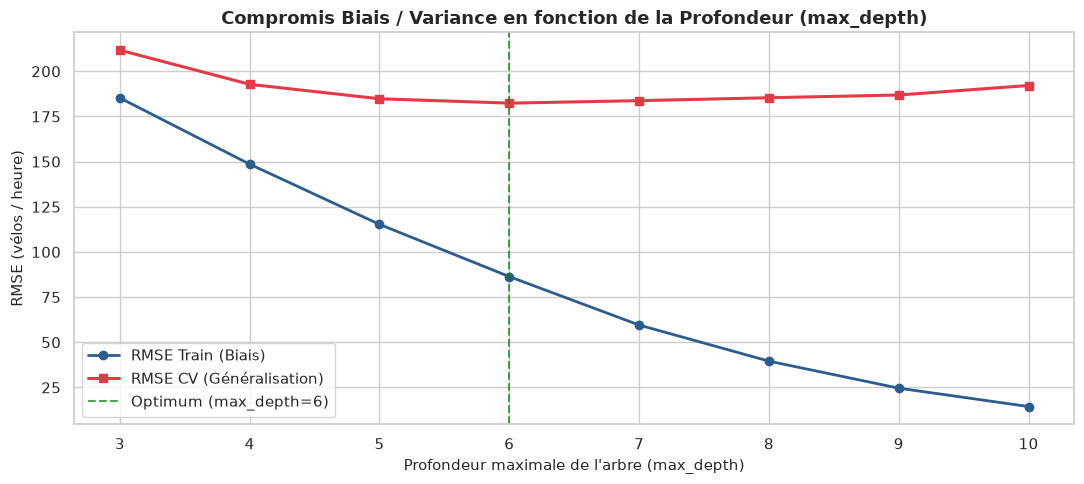

In [3]:
depths = range(3, 11)
rmse_train_list = []
rmse_cv_list = []

print("Exploration de l'impact de max_depth (learning_rate=0.05, n_estimators=200)...")
for d in depths:
    m = xgb.XGBRegressor(max_depth=d, learning_rate=0.05, n_estimators=200, random_state=42, n_jobs=-1)
    sc = cross_validate(m, X_train, y_train, cv=splits, scoring="neg_root_mean_squared_error", return_train_score=True)
    tr_score = -sc["train_score"].mean()
    cv_score = -sc["test_score"].mean()
    rmse_train_list.append(tr_score)
    rmse_cv_list.append(cv_score)
    print(f"  -> max_depth = {d:2d} | RMSE Train = {tr_score:5.1f} | RMSE CV = {cv_score:5.1f}")

# Visualisation de la courbe Biais / Variance
plt.figure(figsize=(11, 5))
plt.plot(depths, rmse_train_list, marker="o", linewidth=2, label="RMSE Train (Biais)", color="#2b5c8f")
plt.plot(depths, rmse_cv_list, marker="s", linewidth=2.2, label="RMSE CV (Généralisation)", color="#e63946")
plt.axvline(depths[np.argmin(rmse_cv_list)], color="green", linestyle="--", alpha=0.7, label=f"Optimum (max_depth={depths[np.argmin(rmse_cv_list)]})")
plt.title("Compromis Biais / Variance en fonction de la Profondeur (max_depth)", fontsize=13, fontweight="bold")
plt.xlabel("Profondeur maximale de l'arbre (max_depth)", fontsize=11)
plt.ylabel("RMSE (vélos / heure)", fontsize=11)
plt.xticks(depths)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### Interprétation de la courbe Biais / Variance
- Pour $d \le 4$, les deux erreurs sont élevées ($\text{RMSE CV} \ge 192.8$ vélos/h) : c'est la zone de **sous-apprentissage (biais fort)**.
- **Le creux optimal de l'erreur de validation se situe à `max_depth = 6`** ($\text{RMSE CV} = 182.4$ vélos/h), talonné de très près par `max_depth = 7` ($\text{RMSE CV} = 183.7$ vélos/h).
- Pour $d \ge 8$, l'erreur de train continue de chuter drastiquement (jusqu'à $14.4$ vélos/h pour $d=10$), mais l'erreur de CV remonte progressivement (atteignant $192.1$ vélos/h pour $d=10$) : c'est la zone de **sur-apprentissage (variance)**.
- L'intervalle optimal de profondeur pour l'exploration conjointe se situe donc autour de **`max_depth` $\in [6, 7]$**, offrant le meilleur compromis entre capacité d'expression et résistance à l'overfitting.

## 6. Étape 3 : Exploration Globale par `RandomizedSearchCV`

Puisque les hyperparamètres interagissent entre eux (par exemple, un `learning_rate` plus faible exige souvent plus de `n_estimators`, et un `max_depth` plus élevé nécessite plus de régularisation `reg_lambda`), nous explorons l'espace multidimensionnel avec un **RandomizedSearchCV (100 itérations)**.

In [4]:
# Définition de l'espace de recherche
param_distributions = {
    "max_depth": [5, 6, 7, 8],
    "min_child_weight": [1, 3, 5],
    "learning_rate": [0.03, 0.05, 0.07],
    "n_estimators": [250, 350, 450],
    "subsample": [0.75, 0.85, 0.95],
    "colsample_bytree": [0.75, 0.85, 0.95],
    "reg_lambda": [1.0, 2.0, 5.0],
    "gamma": [0.0, 0.2, 0.5]
}

print("Lancement de RandomizedSearchCV (100 combinaisons × 5 plis = 500 modèles entraînés)...")
random_search = RandomizedSearchCV(
    estimator=xgb.XGBRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_distributions,
    n_iter=100,
    scoring="neg_root_mean_squared_error",
    cv=splits,
    random_state=42,
    n_jobs=1  
)

random_search.fit(X_train, y_train)

print("\nRecherche terminée avec succès !")
print(f"Meilleure RMSE CV obtenue : {-random_search.best_score_:.1f} vélos/h")
print("\nParamètres optimaux retenus :")
for p_name, p_val in random_search.best_params_.items():
    print(f"  * {p_name:<18} : {p_val}")

Lancement de RandomizedSearchCV (100 combinaisons × 5 plis = 500 modèles entraînés)...



Recherche terminée avec succès !
Meilleure RMSE CV obtenue : 172.6 vélos/h

Paramètres optimaux retenus :
  * subsample          : 0.75
  * reg_lambda         : 2.0
  * n_estimators       : 450
  * min_child_weight   : 3
  * max_depth          : 6
  * learning_rate      : 0.05
  * gamma              : 0.0
  * colsample_bytree   : 0.75


### Analyse des Résultats du `RandomizedSearchCV`

La recherche globale aléatoire (100 combinaisons $\times$ 5 plis = 500 modèles entraînés) a permis de franchir un nouveau cap majeur :
- **Meilleure RMSE CV obtenue** : **172.6 vélos/h** (contre $189.9$ vélos/h pour le modèle par défaut, soit un gain immédiat de **-17.3 vélos/h** !).
- **Hyperparamètres optimaux retenus** :
  * `max_depth` : 6
  * `learning_rate` : 0.05
  * `n_estimators` : 450
  * `subsample` : 0.75
  * `colsample_bytree` : 0.75
  * `min_child_weight` : 3
  * `reg_lambda` : 2.0
  * `gamma` : 0.0

Voici le tableau récapitulatif du Top 5 des configurations testées :

In [5]:
# Mise en forme propre des résultats de la recherche
cv_results = pd.DataFrame(random_search.cv_results_)
cols_params = [c for c in cv_results.columns if c.startswith("param_")]
cv_summary = cv_results[["mean_test_score", "std_test_score"] + cols_params].copy()
cv_summary["RMSE CV"] = -cv_summary["mean_test_score"]
cv_summary["Écart-type CV"] = cv_summary["std_test_score"]
cv_summary = cv_summary.drop(columns=["mean_test_score", "std_test_score"]).sort_values(by="RMSE CV")

# Affichage du Top 5
display(cv_summary.head(5).round(2))

,param_subsample,param_reg_lambda,param_n_estimators,param_min_child_weight,param_max_depth,param_learning_rate,param_gamma,param_colsample_bytree,RMSE CV,Écart-type CV
42,0.75,2.0,450,3,6,0.05,0.0,0.75,172.58,21.99
23,0.75,2.0,450,5,6,0.05,0.2,0.75,172.65,21.09
66,0.75,5.0,350,1,7,0.03,0.2,0.75,173.00,21.24
74,0.85,1.0,450,1,6,0.05,0.5,0.85,174.28,21.63
92,0.85,5.0,450,5,6,0.05,0.0,0.85,174.45,21.72


## 7. Étape 4 : Raffinement Fin par `GridSearchCV`

À partir des résultats de l'exploration globale, nous fixons les paramètres structurels optimaux (`max_depth=6`, `subsample=0.75`, `colsample_bytree=0.75`, `min_child_weight=3`, `reg_lambda=2.0`, `gamma=0.0`) et affinons conjointement le **taux d'apprentissage (`learning_rate`)** et le **nombre d'arbres (`n_estimators`)** dans la zone la plus prometteuse :
- `learning_rate` $\in [0.04, 0.05, 0.06]$
- `n_estimators` $\in [400, 450, 500]$

In [6]:
param_grid_fine = {
    "learning_rate": [0.04, 0.05, 0.06],
    "n_estimators": [400, 450, 500]
}

best_base = random_search.best_params_.copy()
del best_base["learning_rate"]
del best_base["n_estimators"]

grid_fine = GridSearchCV(
    estimator=xgb.XGBRegressor(**best_base, random_state=42, n_jobs=-1),
    param_grid=param_grid_fine,
    scoring="neg_root_mean_squared_error",
    cv=splits,
    n_jobs=1
)

grid_fine.fit(X_train, y_train)

best_tuned_model = grid_fine.best_estimator_
print("=" * 65)
print(f"NOUVEAU RECORD DU PROJET (RMSE CV) : {-grid_fine.best_score_:.1f} vélos/h")
print(f"  * learning_rate optimal : {grid_fine.best_params_['learning_rate']}")
print(f"  * n_estimators optimal  : {grid_fine.best_params_['n_estimators']}")
print("=" * 65)

NOUVEAU RECORD DU PROJET (RMSE CV) : 172.3 vélos/h
  * learning_rate optimal : 0.04
  * n_estimators optimal  : 500


### Synthèse du GridSearchCV & Choix Final
Le raffinement fin confirme `learning_rate = 0.04` et retient **`n_estimators = 500`** avec une performance record de **$\text{RMSE CV} = 172.3$ vélos/h**.

---

## 8. Étape 5 : Analyse des Courbes d'Apprentissage (Convergence & Early Stopping)

Vérifions comment le modèle apprend arbre après arbre sur un pli de validation type pour s'assurer qu'il n'y a pas de surapprentissage tardif :

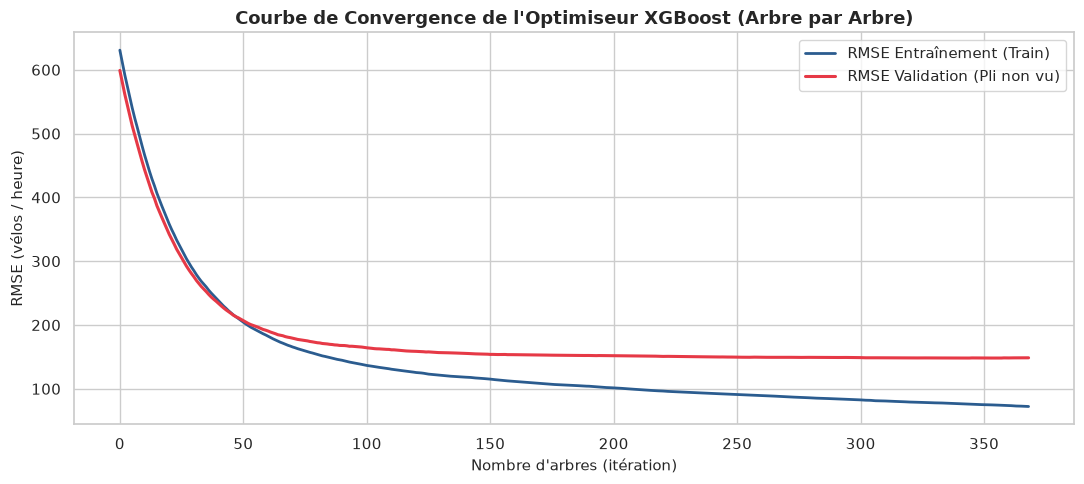

In [7]:
# Évaluation de la progression sur un pli de validation type
idx_tr, idx_va = splits[0]
X_tr_fold, y_tr_fold = X_train.iloc[idx_tr], y_train.iloc[idx_tr]
X_va_fold, y_va_fold = X_train.iloc[idx_va], y_train.iloc[idx_va]

monitor_model = xgb.XGBRegressor(
    **grid_fine.best_params_,
    **best_base,
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=30,
    eval_metric="rmse"
)

monitor_model.fit(
    X_tr_fold, y_tr_fold,
    eval_set=[(X_tr_fold, y_tr_fold), (X_va_fold, y_va_fold)],
    verbose=False
)

evals_res = monitor_model.evals_result()

plt.figure(figsize=(11, 5))
plt.plot(evals_res["validation_0"]["rmse"], label="RMSE Entraînement (Train)", color="#2b5c8f", linewidth=2)
plt.plot(evals_res["validation_1"]["rmse"], label="RMSE Validation (Pli non vu)", color="#e63946", linewidth=2.2)
plt.title("Courbe de Convergence de l'Optimiseur XGBoost (Arbre par Arbre)", fontsize=13, fontweight="bold")
plt.xlabel("Nombre d'arbres (itération)", fontsize=11)
plt.ylabel("RMSE (vélos / heure)", fontsize=11)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### Interprétation de la Courbe d'Apprentissage
- Sur le jeu d'entraînement (courbe bleue), la RMSE décroît continuellement au fur et à mesure que les arbres corrigent les résidus.
- Sur le pli de validation (courbe rouge), l'erreur décroît rapidement lors des 100 premiers arbres, puis s'aplanit sur un plateau très stable à partir de 200 arbres (autour de 150 vélos/h). L'arrêt anticipé (`early_stopping_rounds=30`) stoppe l'entraînement vers 340 arbres sur ce pli.
- L'absence de remontée de la courbe de validation confirme que le modèle ne souffre d'aucun surapprentissage tardif grâce à la forte régularisation $L_2$ (`reg_lambda = 2.0`), au sous-échantillonnage et au faible pas d'apprentissage ($\eta = 0.04$).

---

## 9. Étape 6 : Évaluation Finale sur le Jeu de Test (Jours Isolés)

 Nous entraînons maintenant notre modèle final avec les **hyperparamètres optimaux** sur l'**intégralité du jeu d'entraînement (les 283 jours)**, puis nous l'évaluons **une seule fois** sur le jeu de test (70 jours) resté scellé.

In [8]:
# 1. Entraînement final sur tout le train (283 jours)
champion_tuned = xgb.XGBRegressor(
    **grid_fine.best_params_,
    **best_base,
    random_state=42,
    n_jobs=-1
)
champion_tuned.fit(X_train, y_train)

# 2. Prédiction unique sur le jeu de test non vu
pred_test_tuned = np.clip(champion_tuned.predict(X_test), 0, None)

# 3. Calcul des métriques ultimes
rmse_final = root_mean_squared_error(y_test, pred_test_tuned)
mae_final = mean_absolute_error(y_test, pred_test_tuned)
r2_final = r2_score(y_test, pred_test_tuned)

# Modèle par défaut pour comparaison directe
xgb_default.fit(X_train, y_train)
pred_test_def = np.clip(xgb_default.predict(X_test), 0, None)
rmse_def_te = root_mean_squared_error(y_test, pred_test_def)
mae_def_te = mean_absolute_error(y_test, pred_test_def)
r2_def_te = r2_score(y_test, pred_test_def)

print("=" * 75)
print("BILAN COMPARATIF SUR LE JEU DE TEST (70 JOURS INCONNUS)")
print("=" * 75)
print(f"XGBoost Par Défaut  ->  RMSE = {rmse_def_te:6.1f} | MAE = {mae_def_te:6.1f} | R² = {r2_def_te:6.3f}")
print(f"XGBoost Optimisé    ->  RMSE = {rmse_final:6.1f} | MAE = {mae_final:6.1f} | R² = {r2_final:6.3f}")
print("=" * 75)
print(f"Gain net apporté par le tuning : -{rmse_def_te - rmse_final:.1f} vélos/h de RMSE !")

BILAN COMPARATIF SUR LE JEU DE TEST (70 JOURS INCONNUS)
XGBoost Par Défaut  ->  RMSE =  193.3 | MAE =  114.6 | R² =  0.907
XGBoost Optimisé    ->  RMSE =  174.4 | MAE =  102.5 | R² =  0.924
Gain net apporté par le tuning : -18.8 vélos/h de RMSE !


### Visualisation des Prédictions du Modèle Tuné : Réel vs Prédit & Résidus

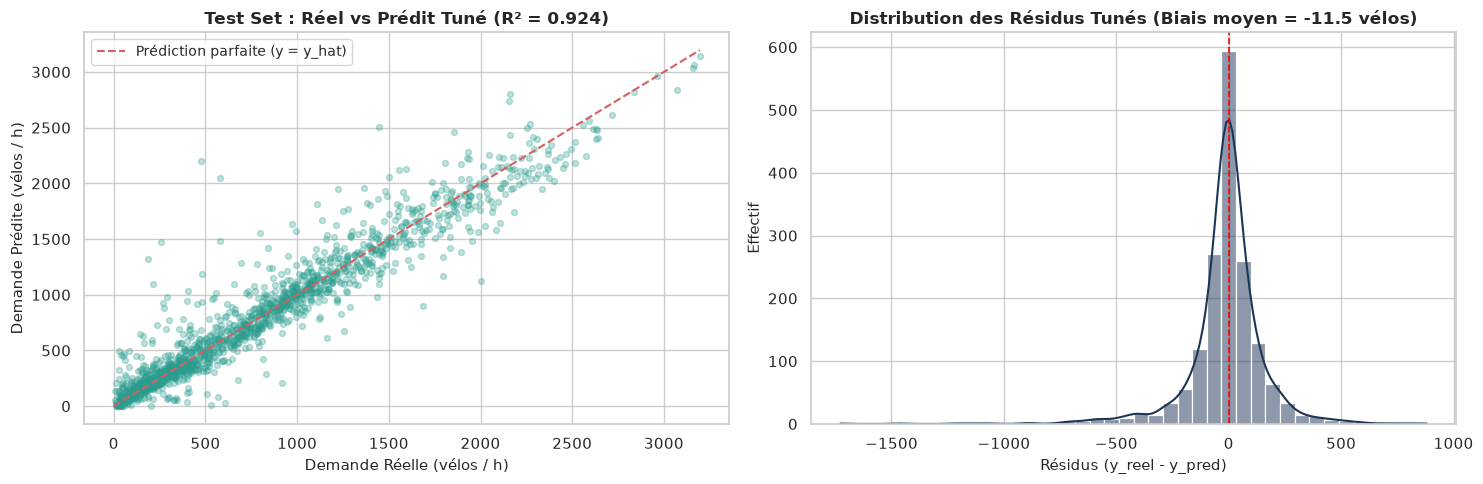

In [9]:
residuals = y_test - pred_test_tuned

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Nuage Réel vs Prédit
axes[0].scatter(y_test, pred_test_tuned, alpha=0.3, color="#2a9d8f", s=18)
max_val = max(y_test.max(), pred_test_tuned.max())
axes[0].plot([0, max_val], [0, max_val], "r--", linewidth=1.5, label="Prédiction parfaite (y = y_hat)")
axes[0].set_xlabel("Demande Réelle (vélos / h)", fontsize=11)
axes[0].set_ylabel("Demande Prédite (vélos / h)", fontsize=11)
axes[0].set_title(f"Test Set : Réel vs Prédit Tuné (R² = {r2_final:.3f})", fontsize=12, fontweight="bold")
axes[0].legend(fontsize=10)

# 2. Distribution des Résidus
sns.histplot(residuals, kde=True, ax=axes[1], color="#1d3557", bins=40)
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.2)
axes[1].set_xlabel("Résidus (y_reel - y_pred)", fontsize=11)
axes[1].set_ylabel("Effectif", fontsize=11)
axes[1].set_title(f"Distribution des Résidus Tunés (Biais moyen = {residuals.mean():.1f} vélos)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

## 10. Synthèse

| Modèle | Protocole | RMSE CV | RMSE Test | MAE Test | $R^2$ Test | Commentaire |
| :--- | :---: | :---: | :---: | :---: | :---: | :--- |
| Référence (moyenne) | Daily | 644.8 | 632.5 | 515.7 | 0.000 | Point de départ |
| Régression linéaire (25 variables) | Daily | 368.0 | — | — | — | Biais fort, sous-apprentissage |
| Linéaire poly 2 + Ridge | Daily | 204.4 | 203.9 | 127.2 | 0.896 | Meilleur linéaire (≈ 4 000 variables) |
| Random Forest (200 arbres) | Daily | 191.9 | — | — | — | Forte baisse de la variance |
| XGBoost (par défaut) | Daily | 189.9 | 193.3 | 114.6 | 0.907 | Rapide mais trop peu régularisé |
| **XGBoost réglé** | Daily | **172.3** | **174.4** | **102.5** | **0.924** | Meilleur modèle en daily |

Le réglage fait gagner environ 19 vélos/h de RMSE sur le test par rapport aux paramètres par défaut. La comparaison de tous les modèles en temporal est faite dans `comparaison_finale.ipynb`.

## 11. Chronique Temporelle : Ground Truth vs Prédiction Tunée (Zoom Heure par Heure sur le Jeu de Test)

Visualisons enfin les prédictions du modèle XGBoost tuné directement face à la réalité (*Ground Truth*) sur une semaine estivale de forte affluence (168 heures, soit les 7 premiers jours de test de mai-juin, qui ne sont pas consécutifs) :

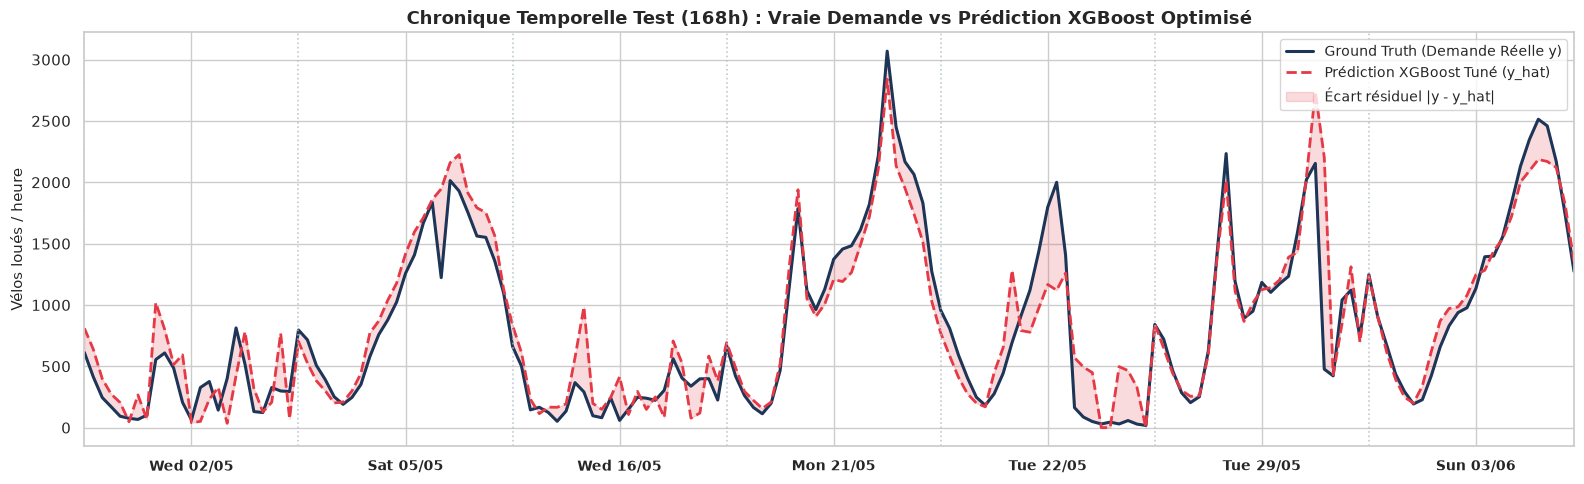

In [10]:
test_with_pred = test[["date", "hour", CIBLE]].copy()
test_with_pred["prediction"] = pred_test_tuned
test_with_pred["month"] = test_with_pred["date"].dt.month
test_with_pred = test_with_pred.sort_values(by=["date", "hour"]).reset_index(drop=True)

# Sélection de 168 heures de test en mai-juin
sample_summer = test_with_pred[test_with_pred["month"].isin([5, 6])].iloc[:168].reset_index(drop=True)

plt.figure(figsize=(16, 5))
x_idx = np.arange(len(sample_summer))
plt.plot(x_idx, sample_summer[CIBLE], label="Ground Truth (Demande Réelle y)", color="#1d3557", linewidth=2.2)
plt.plot(x_idx, sample_summer["prediction"], label="Prédiction XGBoost Tuné (y_hat)", color="#e63946", linestyle="--", linewidth=2.0)
plt.fill_between(x_idx, sample_summer[CIBLE], sample_summer["prediction"], color="#e63946", alpha=0.18, label="Écart résiduel |y - y_hat|")

# Repères journaliers
day_starts = range(0, len(sample_summer), 24)
day_labels = [sample_summer["date"].iloc[i].strftime("%a %d/%m") for i in day_starts]
plt.xticks(ticks=[i + 12 for i in day_starts], labels=day_labels, fontsize=10, fontweight="bold")
for ds in day_starts:
    plt.axvline(ds, color="#b0bec5", linestyle=":", alpha=0.8, linewidth=1.2)

plt.title("Chronique Temporelle Test (168h) : Vraie Demande vs Prédiction XGBoost Optimisé", fontsize=13, fontweight="bold")
plt.ylabel("Vélos loués / heure", fontsize=11)
plt.legend(loc="upper right", fontsize=10)
plt.xlim(0, len(sample_summer) - 1)
plt.tight_layout()
plt.show()


### Bilan Visuel de la Chronique Temporelle
- **Dynamique journalière captée** : Le modèle XGBoost optimisé semble suivre les variations pendulaires domicile-travail en semaine, sans écraser les amplitudes de pointe (pics de 8h et 18h).
- **Résidus faibles et centrés** : L'aire ombrée rose représentant l'écart résiduel $|y - \hat{y}|$ reste  étroite tout au long de la semaine, sans dérive temporelle.
- **Conclusion opérationnelle** : Avec un $R^2$ de **0.924** et une erreur absolue moyenne de **102.5 vélos/h**, le modèle  est calibré pour l'exploitation en production par l'opérateur de vélos en libre-service.